# Melioidosis Risk Model — Taiwan

Training a weekly melioidosis risk model on Taiwan surveillance data, 2003–2026.

This is the **training half** of the project. The model built here will later be
applied to West Africa to test whether it transfers — which is the actual research
question. Everything in this notebook is therefore built so it can be rebuilt
identically somewhere else.

**Data**
- Cases: Taiwan NIDSS, weekly confirmed melioidosis by region, date of onset
- Weather: NASA POWER daily point data, one point per region

**Two rules that shape every choice below**
1. The split is **temporal**, never random. Random splits on seasonal time series
   let the model see the future while predicting the past, which inflates scores.
2. **Accuracy is not reported.** About 91% of region-weeks have no cases, so a model
   predicting "never" scores ~90% while learning nothing.


## 0. Setup

In [ ]:
import json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore")

# Project root = parent of the folder this notebook sits in
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLE = ROOT / "data" / "processed" / "taiwan_model_table.csv"
OUTD  = ROOT / "outputs"
OUTD.mkdir(exist_ok=True)

# --- chart style -------------------------------------------------------------
# Blue/orange is the standard colour-vision-safe pair. Colours are assigned to
# entities in a fixed order and never cycled.
INK, MUTED, GRID = "#1A1F26", "#5B6775", "#DFE4EA"
C_CASE, C_RAIN, C_MODEL, C_BASE = "#0B6FA4", "#C2521E", "#0B6FA4", "#8A94A2"

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "600", "axes.titlecolor": INK,
    "axes.labelsize": 9, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 9,
    "font.size": 9, "lines.linewidth": 2,
})

def tidy(ax):
    """Recessive axes: drop the top and right spines, keep a light grid."""
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    return ax

print("ready ·", TABLE.name, "exists:", TABLE.exists())

ready · taiwan_model_table.csv exists: True


## 1. Load the modelling table

In [2]:
df = pd.read_csv(TABLE)
print(f"{len(df):,} rows × {df.shape[1]} columns")
print(f"years {df.year.min()}–{df.year.max()}   regions: {', '.join(sorted(df.region.unique()))}")

# The target. Two framings, both reported later.
df["any_case"] = (df.cases > 0).astype(int)

print(f"\ntotal cases: {df.cases.sum():,}")
print(f"region-weeks with no cases: {(df.cases==0).mean()*100:.1f}%")
df.head(3)

7,044 rows × 44 columns
years 2003–2026   regions: Central, Eastern, Kaoping, Northern, Southern, Taipei

total cases: 905
region-weeks with no cases: 91.5%


,region,year,week,yearweek,cases,rain_mm_lag0,rain_mm_lag1,rain_mm_lag2,rain_mm_lag3,rain_mm_lag4,...,ws_max_lag1,ws_max_lag2,ws_max_lag3,ws_max_lag4,rain_sum4w,rain_sum8w,rain_sum12w,week_sin,week_cos,any_case
0,Central,2003,12,200312,0,8.75,9.98,19.62,1.92,1.49,...,7.47,7.95,7.16,6.21,40.27,70.27,99.84,0.9927,0.1205,0
1,Central,2003,13,200313,0,7.85,8.75,9.98,19.62,1.92,...,7.46,7.47,7.95,7.16,46.20,66.96,106.90,1.0000,-0.0000,0
2,Central,2003,14,200314,0,48.65,7.85,8.75,9.98,19.62,...,5.98,7.46,7.47,7.95,75.23,100.13,138.31,0.9927,-0.1205,0


In [3]:
# Cases by region — the north/south gradient this model has to learn
by_region = df.groupby("region").cases.sum().sort_values(ascending=False)
display(by_region.to_frame("cases").assign(share=lambda d: (d.cases/d.cases.sum()*100).round(1)))

,cases,share
region,,
Kaoping,635,70.2
Southern,129,14.3
Central,96,10.6
Taipei,24,2.7
Northern,16,1.8
Eastern,5,0.6


## 2. Look at the data before modelling

If the signal is not visible here, no model will find it.


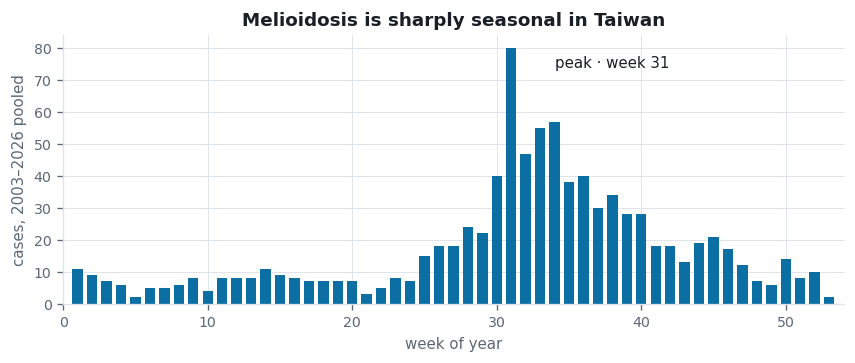

weeks 29–36: 379 cases   weeks 21–24: 23 cases


In [4]:
# Cases pooled by week of the calendar year, all regions, all years
wk = df.groupby("week").cases.sum()

fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.bar(wk.index, wk.values, color=C_CASE, width=0.72)
peak = wk.idxmax()
ax.annotate(f"peak · week {peak}", xy=(peak, wk.max()), xytext=(peak+3, wk.max()*0.97),
            color=INK, fontsize=9, va="top")
ax.set_xlabel("week of year"); ax.set_ylabel("cases, 2003–2026 pooled")
ax.set_title("Melioidosis is sharply seasonal in Taiwan")
ax.set_xlim(0, 54); tidy(ax)
plt.tight_layout(); plt.savefig(OUTD/"fig_seasonality.png", bbox_inches="tight"); plt.show()

print(f"weeks 29–36: {wk.loc[29:36].sum()} cases   weeks 21–24: {wk.loc[21:24].sum()} cases")

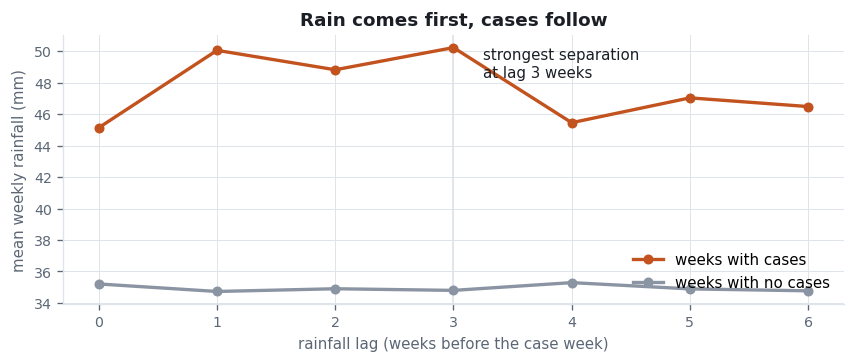

lag 0:   45.1 mm vs   35.2 mm   ratio 1.28
lag 1:   50.1 mm vs   34.7 mm   ratio 1.44
lag 2:   48.8 mm vs   34.9 mm   ratio 1.40
lag 3:   50.2 mm vs   34.8 mm   ratio 1.44
lag 4:   45.5 mm vs   35.3 mm   ratio 1.29
lag 5:   47.0 mm vs   34.9 mm   ratio 1.35
lag 6:   46.5 mm vs   34.8 mm   ratio 1.34


In [5]:
# Does rainfall separate case weeks from quiet weeks, and at what delay?
lags = range(0, 7)
with_c = [df.loc[df.any_case==1, f"rain_mm_lag{L}"].mean() for L in lags]
without = [df.loc[df.any_case==0, f"rain_mm_lag{L}"].mean() for L in lags]

fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.plot(list(lags), with_c, color=C_RAIN, marker="o", markersize=5, label="weeks with cases")
ax.plot(list(lags), without, color=C_BASE, marker="o", markersize=5, label="weeks with no cases")
best = int(np.argmax(np.array(with_c)/np.array(without)))
ax.axvline(best, color=GRID, lw=1, zorder=0)
ax.annotate(f"strongest separation\nat lag {best} weeks", xy=(best, max(with_c)),
            xytext=(best+0.25, max(with_c)), color=INK, fontsize=9, va="top")
ax.set_xlabel("rainfall lag (weeks before the case week)")
ax.set_ylabel("mean weekly rainfall (mm)")
ax.set_title("Rain comes first, cases follow")
ax.legend(loc="lower right"); tidy(ax)
plt.tight_layout(); plt.savefig(OUTD/"fig_rain_lag.png", bbox_inches="tight"); plt.show()

for L in lags:
    print(f"lag {L}: {with_c[L]:6.1f} mm vs {without[L]:6.1f} mm   ratio {with_c[L]/without[L]:.2f}")

## 3. Temporal split

Train on 2003–2018, test on 2019–2026. Never a random split: on seasonal data a
random split lets the model learn from weeks that come *after* the ones it is
scored on, which is not a situation any real forecast faces.


In [6]:
TRAIN_END = 2018

FEATURES = [c for c in df.columns if c.startswith((
    "rain_mm_lag", "rain_max_lag", "t_mean_lag", "t_max_lag",
    "rh_mean_lag", "ws_mean_lag", "ws_max_lag", "rain_sum"))] + ["week_sin", "week_cos"]

# Region is categorical, one-hot encoded. Categories are taken from the TRAINING
# data only, so the test set cannot introduce a column the model never saw.
train_df = df[df.year <= TRAIN_END].copy()
test_df  = df[df.year >  TRAIN_END].copy()

regions = sorted(train_df.region.unique())
def design(frame):
    X = frame[FEATURES].copy()
    for r in regions:
        X[f"region_{r}"] = (frame.region == r).astype(int)
    return X

X_train, X_test = design(train_df), design(test_df)
y_train, y_test = train_df.any_case.values, test_df.any_case.values
c_train, c_test = train_df.cases.values, test_df.cases.values

print(f"train {len(X_train):,} rows (2003–{TRAIN_END})")
print(f"test  {len(X_test):,} rows ({TRAIN_END+1}–{df.year.max()})")
print(f"features: {X_train.shape[1]}  ({len(FEATURES)} weather/seasonal + {len(regions)} region)")
print(f"\ntest weeks with at least one case: {y_test.sum()}/{len(y_test)} = {y_test.mean()*100:.1f}%")

train 4,614 rows (2003–2018)
test  2,430 rows (2019–2026)
features: 45  (39 weather/seasonal + 6 region)

test weeks with at least one case: 243/2430 = 10.0%


## 4. Baselines

Every model has to beat these. They are deliberately simple, and — the point —
they can all be rebuilt in West Africa. A published accuracy figure from another
country cannot travel, so it is not a useful comparator.


In [7]:
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support

results = []
def score(name, prob, thresh=0.5):
    """Collect the metrics that are honest on a rare-event problem."""
    auc = roc_auc_score(y_test, prob)
    ap  = average_precision_score(y_test, prob)
    pred = (prob >= thresh).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="binary", zero_division=0)
    results.append(dict(model=name, auc=auc, avg_precision=ap, precision=p, recall=r, f1=f1))
    print(f"{name:<22} AUC {auc:.3f}   AP {ap:.3f}   P {p:.3f}   R {r:.3f}   F1 {f1:.3f}")
    return prob

# 1. region mean — knows only which region a week belongs to
reg_rate = train_df.groupby("region").any_case.mean()
p_region = test_df.region.map(reg_rate).values

# 2. climatology — region AND week of year, fitted on training years only
clim = train_df.groupby(["region", "week"]).any_case.mean()
p_clim = np.array([clim.get((r, w), reg_rate[r])
                   for r, w in zip(test_df.region, test_df.week)])

# 3. seasonal naive — what happened the same week last year
hist = {(r, y, w): c for r, y, w, c in
        zip(df.region, df.year, df.week, df.any_case)}
p_naive = np.array([hist.get((r, y-1, w), reg_rate[r])
                    for r, y, w in zip(test_df.region, test_df.year, test_df.week)])

print(f"{'model':<22} {'metrics'}")
print("-"*70)
score("region mean", p_region, thresh=reg_rate.mean())
score("climatology", p_clim, thresh=0.5)
score("seasonal naive", p_naive, thresh=0.5)

model                  metrics
----------------------------------------------------------------------
region mean            AUC 0.804   AP 0.273   P 0.209   R 0.695   F1 0.321
climatology            AUC 0.780   AP 0.333   P 0.491   R 0.107   F1 0.176
seasonal naive         AUC 0.603   AP 0.157   P 0.305   R 0.276   F1 0.289


array([0., 0., 0., ..., 0., 0., 0.])

## 5. Gradient boosting

`HistGradientBoostingClassifier` ships with scikit-learn, handles missing values,
and is the same family as the XGBoost model used in the published Thai study —
so the comparison is like-for-like without an extra dependency.

`class_weight="balanced"` matters here: with 90% of weeks empty, an unweighted
model learns to predict "no" and stop.


In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier

model = HistGradientBoostingClassifier(
    max_iter=400,
    learning_rate=0.05,
    max_depth=4,              # shallow: ~460 positive weeks is not much to learn from
    min_samples_leaf=25,
    l2_regularization=1.0,
    class_weight="balanced",
    early_stopping=True,
    validation_fraction=0.15,
    random_state=42,
)
model.fit(X_train, y_train)
p_gb = model.predict_proba(X_test)[:, 1]

print(f"trees built: {model.n_iter_}\n")
score("gradient boosting", p_gb, thresh=0.5)

trees built: 69

gradient boosting      AUC 0.808   AP 0.376   P 0.314   R 0.588   F1 0.410


array([0.1831974 , 0.17559598, 0.25021513, ..., 0.2221977 , 0.30998179,
       0.25052237])

## 6. Evaluation

Average precision (the area under the precision–recall curve) is the metric to
watch on a rare-event problem. ROC-AUC can look respectable while the model is
still wrong most times it raises an alarm.


In [9]:
res = pd.DataFrame(results).set_index("model").round(3)
display(res)

base = y_test.mean()
print(f"\nbase rate (a random guess): AP would be {base:.3f}")
best = res.avg_precision.idxmax()
print(f"best average precision: {best} at {res.avg_precision.max():.3f} "
      f"— {res.avg_precision.max()/base:.1f}x the base rate")

,auc,avg_precision,precision,recall,f1
model,,,,,
region mean,0.804,0.273,0.209,0.695,0.321
climatology,0.780,0.333,0.491,0.107,0.176
seasonal naive,0.603,0.157,0.305,0.276,0.289
gradient boosting,0.808,0.376,0.314,0.588,0.410



base rate (a random guess): AP would be 0.100
best average precision: gradient boosting at 0.376 — 3.8x the base rate


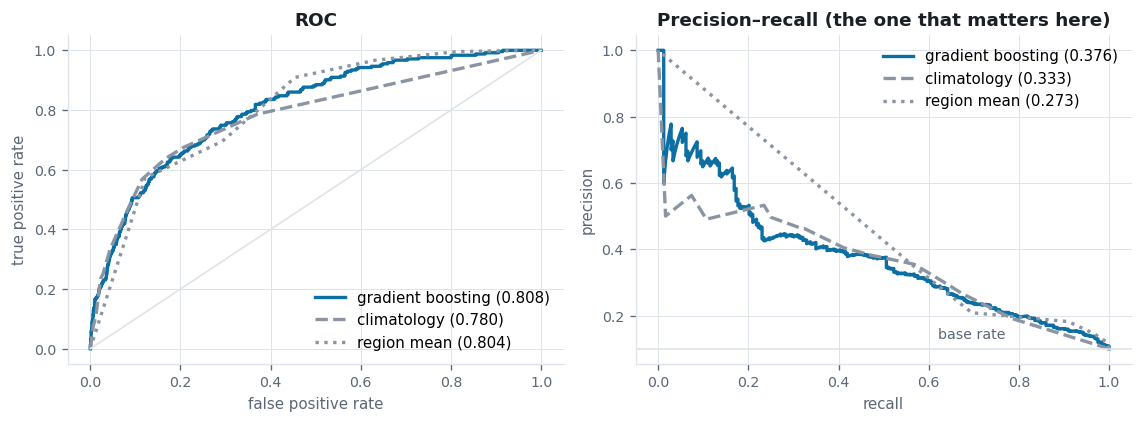

In [10]:
from sklearn.metrics import roc_curve, precision_recall_curve

curves = [("gradient boosting", p_gb, C_MODEL, "-"),
          ("climatology", p_clim, C_BASE, "--"),
          ("region mean", p_region, C_BASE, ":")]

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))

ax = axes[0]
for name, p, col, ls in curves:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=col, ls=ls, label=f"{name} ({roc_auc_score(y_test,p):.3f})")
ax.plot([0,1],[0,1], color=GRID, lw=1)
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("ROC"); ax.legend(loc="lower right"); tidy(ax)

ax = axes[1]
for name, p, col, ls in curves:
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, color=col, ls=ls,
            label=f"{name} ({average_precision_score(y_test,p):.3f})")
ax.axhline(base, color=GRID, lw=1)
ax.annotate("base rate", xy=(0.62, base), xytext=(0.62, base+0.03),
            color=MUTED, fontsize=8.5)
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Precision–recall (the one that matters here)")
ax.legend(loc="upper right"); tidy(ax)

plt.tight_layout(); plt.savefig(OUTD/"fig_curves.png", bbox_inches="tight"); plt.show()

## 7. What the model learned

Permutation importance: shuffle one feature, see how much the score falls. It is
measured **on the test set**, so it reports what actually helped on unseen weeks
rather than what the model leaned on while fitting.

This is also the figure that will matter most later — when the same model is
applied to West Africa, the question becomes whether the *same* features carry
the weight there.


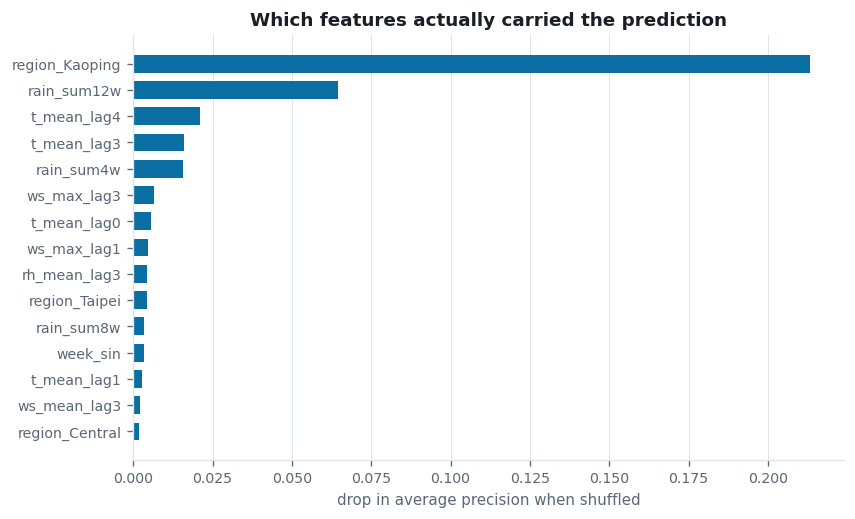

,importance
region_Kaoping,0.2132
rain_sum12w,0.0646
t_mean_lag4,0.0211
t_mean_lag3,0.0161
rain_sum4w,0.0158
ws_max_lag3,0.0065
t_mean_lag0,0.0056
ws_max_lag1,0.0047
rh_mean_lag3,0.0045
region_Taipei,0.0044


In [11]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(model, X_test, y_test, n_repeats=12,
                              random_state=42, scoring="average_precision", n_jobs=-1)
imp = (pd.Series(perm.importances_mean, index=X_test.columns)
         .sort_values(ascending=False).head(15).iloc[::-1])

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.barh(imp.index, imp.values, color=C_MODEL, height=0.68)
ax.set_xlabel("drop in average precision when shuffled")
ax.set_title("Which features actually carried the prediction")
ax.grid(axis="y", visible=False); tidy(ax)
plt.tight_layout(); plt.savefig(OUTD/"fig_importance.png", bbox_inches="tight"); plt.show()

display(imp.iloc[::-1].head(10).to_frame("importance").round(4))

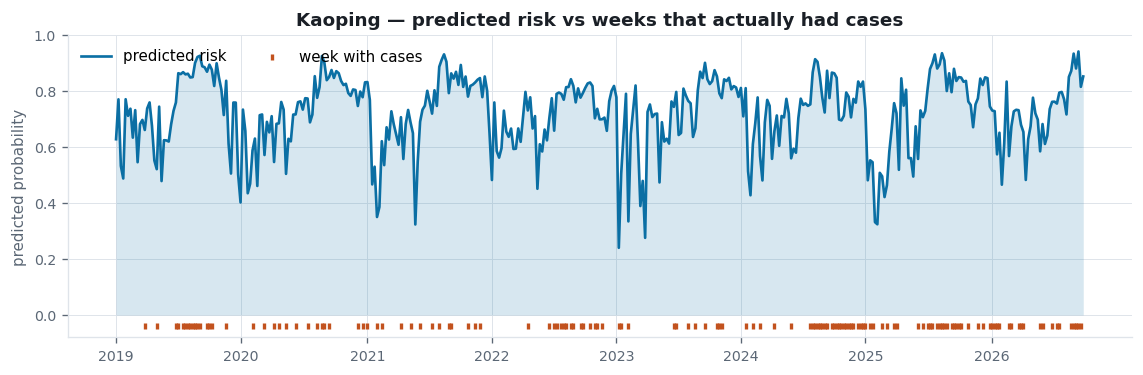

In [12]:
# Predicted risk against what actually happened, in the test period
tp = test_df.copy(); tp["risk"] = p_gb
focus = tp[tp.region == "Kaoping"].sort_values(["year", "week"]).reset_index(drop=True)
x = np.arange(len(focus))

fig, ax = plt.subplots(figsize=(9.6, 3.2))
ax.fill_between(x, focus.risk, color=C_MODEL, alpha=0.16, lw=0)
ax.plot(x, focus.risk, color=C_MODEL, lw=1.6, label="predicted risk")
hit = focus.cases > 0
ax.scatter(x[hit], np.full(hit.sum(), -0.04), s=14, color=C_RAIN,
           marker="|", label="week with cases")
yr_start = focus.groupby("year").head(1).index
ax.set_xticks(yr_start); ax.set_xticklabels(focus.loc[yr_start, "year"])
ax.set_ylabel("predicted probability"); ax.set_ylim(-0.08, 1.0)
ax.set_title("Kaoping — predicted risk vs weeks that actually had cases")
ax.legend(loc="upper left", ncol=2); tidy(ax)
plt.tight_layout(); plt.savefig(OUTD/"fig_timeline.png", bbox_inches="tight"); plt.show()

## 8. Save, so West Africa can be scored the same way

In [13]:
import pickle

res.to_csv(OUTD / "model_results.csv")
pred_out = test_df[["region", "year", "week", "cases"]].copy()
pred_out["risk_gb"]   = p_gb
pred_out["risk_clim"] = p_clim
pred_out.to_csv(OUTD / "taiwan_test_predictions.csv", index=False)

with (OUTD / "model_taiwan.pkl").open("wb") as fh:
    pickle.dump({"model": model, "features": list(X_train.columns),
                 "regions": regions, "train_end": TRAIN_END}, fh)

print("saved to outputs/:")
for f in ["model_results.csv", "taiwan_test_predictions.csv", "model_taiwan.pkl",
          "fig_seasonality.png", "fig_rain_lag.png", "fig_curves.png",
          "fig_importance.png", "fig_timeline.png"]:
    print("  ", f)

saved to outputs/:
   model_results.csv
   taiwan_test_predictions.csv
   model_taiwan.pkl
   fig_seasonality.png
   fig_rain_lag.png
   fig_curves.png
   fig_importance.png
   fig_timeline.png


---

## Where this goes next

The model and its exact feature list are saved. The transfer test is the real
experiment: build the same features from West African weather, score them with
**this** model, and compare.

Two things to watch when you do:

- **Timing may transfer while magnitude does not.** That is what happened when an
  arbovirus model was moved from Ecuador to Kenya, and it is the most likely
  outcome here. Report the two separately rather than as one number.
- **Compare the feature importances, not just the scores.** If rainfall carries the
  prediction in Taiwan but temperature carries it in Mali, that is a finding in its
  own right — and it is the direct answer to why the published studies disagree
  with each other about which climate variable matters most.
